In [1]:
%pylab inline
import os
import gc
import fitsio
import csutil
import numpy as np
import catutil
import astropy.io.ascii as ascii
import astropy.table as astTab

Populating the interactive namespace from numpy and matplotlib


In [2]:
def get_CS_SNR(rnom,xip_G,xim_G,xipC_G,ximC_G,xicC_G,min_p_theta=4.,min_m_theta=20):
    idp0 = np.sum(rnom<min_p_theta)
    cov_p= xipC_G[idp0:,idp0:]
    xip  = xip_G[idp0:]
    SNp  = (np.transpose(xip).dot(np.linalg.inv(cov_p).dot(xip)))**0.5
    psize=len(xip)
    #SNpUC = (np.transpose(xip).dot(np.linalg.inv(np.diag(cov_p.diagonal())).dot(xip)))**0.5

    idm0 = np.sum(rnom<min_m_theta)
    cov_m= ximC_G[idm0:,idm0:]
    xim  = xim_G[idm0:]
    SNm   = (np.transpose(xim).dot(np.linalg.inv(cov_m).dot(xim)))**0.5
    msize=len(xim)

    cov_pm= xicC_G[idp0:,idm0:]

    xiAll= np.append(xip,xim)

    cov_full = np.zeros((msize+psize,msize+psize))
    for i in range(psize+msize):
        for j in range(psize+msize):
            if i<psize and j<psize:
                cov_full[i][j] = cov_p[i][j]
            elif i<psize and j>=psize:
                cov_full[i][j] = cov_pm[i][j-psize]
            elif i>=psize and j<psize:
                cov_full[i][j] = cov_pm.T[i-psize][j]
            elif i>=psize and j>=psize:
                cov_full[i][j] = cov_m[i-psize][j-psize]

    SNAll   = (np.transpose(xiAll).dot(np.linalg.inv(cov_full).dot(xiAll)))**0.5
    return SNp,SNm,SNAll

In [3]:
if False:
    # The first line of the new version treecorr need to be deleted
    pend='GE0'
    for isim in range(108):
        for irot in range(13):
            fname=os.path.join('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/cosmicShear/covariance-wozcut/','sim-%03d' %isim,'rotmat%d_cor%s.csv' %(irot,pend))
            a_file = open(fname,'r')
            lines = a_file.readlines()
            a_file.close()
            if lines[0][0:2]=='##':
                del lines[0]
                new_file = open(fname,'w')
                for line in lines:
                    new_file.write(line)

In [4]:
datDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/cosmicShear/covariance-wozcut/'
csTask=csutil.cs_covariance(datDir)
rnom0,xip_G0,xim_G0=csTask.getAve('G')

In [5]:
if False:
    xipC_E0,ximC_E0,xicC_E0=csTask.getCovMat('E0')
    xipC_G,ximC_G,xicC_G=csTask.getCovMat('G')
    xipC_GE0,ximC_GE0,xicC_GE0=csTask.getCovMat('GE0')

In [6]:
# Average
rnom,xip_G,xim_G=csTask.getAve('E1')
xip_G=xip_G/(2*0.847)**2.
xim_G=xim_G/(2*0.847)**2.
# Cov
xipC_E1,ximC_E1,xicC_E1=csTask.getCovMat('E1')
xipC_G=xipC_E1/(2*0.847)**4.
ximC_G=ximC_E1/(2*0.847)**4.
xicC_G=xicC_E1/(2*0.847)**4.
# Errorbar
xip_err=np.array(np.sqrt(xipC_E1.diagonal()/(2*0.847)**2.)).reshape(30)
xim_err=np.array(np.sqrt(ximC_E1.diagonal()/(2*0.847)**2.)).reshape(30)

(18.17150114610542, 17.365192103136906, 19.38107168581699)

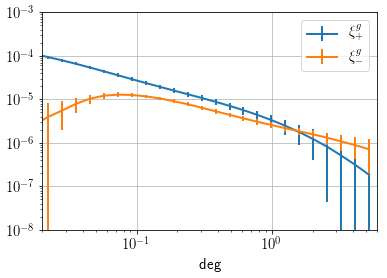

In [7]:
# plot average
plt.close()
plt.errorbar(rnom/60.,xip_G,xip_err,label=r'$\xi_{+}^{g}$')
plt.errorbar(rnom/60.,xim_G,xim_err,label=r'$\xi_{-}^{g}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('deg',fontsize=15)
plt.ylim(1e-8,1e-3)
plt.xlim(2e-2,6.)
plt.grid()
plt.legend(fontsize=15)
get_CS_SNR(rnom,xip_G,xim_G,xipC_G,ximC_G,xicC_G,min_p_theta=4.0,min_m_theta=20.)

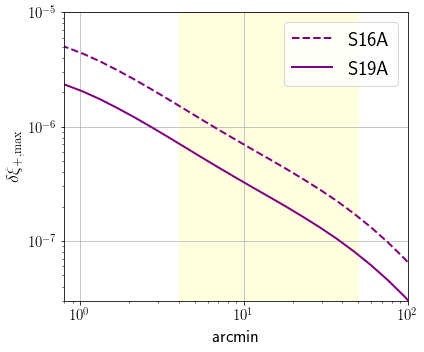

In [31]:
# Maximum systematics error
plt.close()
fig=plt.figure(figsize=(6,5))
ax=fig.add_subplot(1,1,1)
ax.plot(rnom,xip_G/25.2,label='S16A',c='purple',ls='--')
ax.plot(rnom,xip_G/54.,label='S19A',c='purple')
ax.axvspan(4,50, color='lightyellow')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('arcmin')
ax.set_ylabel(r'$\delta\xi_{+,{\rm max}}$')
ax.set_ylim(3e-8,1e-5)
ax.set_xlim(0.8,100)
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('HSC_requirement_cosmicShear.png')

At scale 4 arcmin:  0.0002846060317345475
At scale 50 arcmin:  5.796212929335543e-05
Average: 0.00012843820151756512
da: 0.0113330579067419


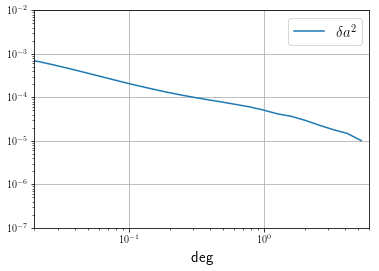

In [76]:
from scipy.interpolate import interp1d
cor_EP=ascii.read('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/ePSF_cov.csv')['xip']
a2req=xip_G/39./cor_EP
# plot average
plt.close()
plt.plot(rnom/60.,a2req,label=r'$\delta a^2$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('deg',fontsize=15)
plt.ylim(1e-7,1e-2)
plt.xlim(2e-2,6.)
plt.grid()
plt.legend(fontsize=15)
xip_spl = interp1d(np.log(rnom), np.log(a2req), kind="cubic")
tmin=4;tmax=50
print('At scale 4 arcmin: ',np.exp(xip_spl(np.log(tmin))))
print('At scale 50 arcmin: ',np.exp(xip_spl(np.log(tmax))))
print('Average:', (np.sqrt(np.exp(xip_spl(np.log(tmax)))*np.exp(xip_spl(np.log(tmin))))))
print('da:', np.sqrt(np.sqrt(np.exp(xip_spl(np.log(tmax)))*np.exp(xip_spl(np.log(tmin))))))

In [6]:
dataCols=[rnom/60.,xip_G/54.,xip_G/108./0.02]

In [7]:
astTab.Table(data=dataCols,names=['rr','rho134','rho25']).write('wrkDir/s19/s19-pre/psf_test_from_wentao/plot_issues/rho_requirements.csv')